# PH5720 — Problem Set 7
**Department of Physics | IIT Madras | January–May 2025**


## Q1


In [1]:
import math


def f(x):
    if x <= 0: 
        return float('inf')
    return math.exp(x) * math.log(x) - math.cos(x)

# Bisection method implementation
def bisection_method(a, b, tol=1e-6, max_iter=100):
    if f(a) * f(b) >= 0:
        print("The bisection method cannot be applied. f(a) and f(b) must have opposite signs.")
        return None

    iteration = 0
    while (b - a) / 2 > tol and iteration < max_iter:
        c = (a + b) / 2
        if f(c) == 0:    
            return c
        elif f(a) * f(c) < 0:
            b = c  
        else:
            a = c 
        
        iteration += 1

    return (a + b) / 2  

# Interval [a, b]
a = 0.1  
b = 4


root = bisection_method(a, b)

if root is not None:
    print(f"The root of the equation in the interval [{a}, {b}] is approximately: {root:.6f}")


The root of the equation in the interval [0.1, 4] is approximately: 1.141943


## Q2

Zero derivative. No solution found.
Solution with x0=0.05: 0.06242222222222221, Steps: 2
Solution with x0=0.11: None, Steps: 1
Solution with x0=0.1: 0.06315888783266142, Steps: 5


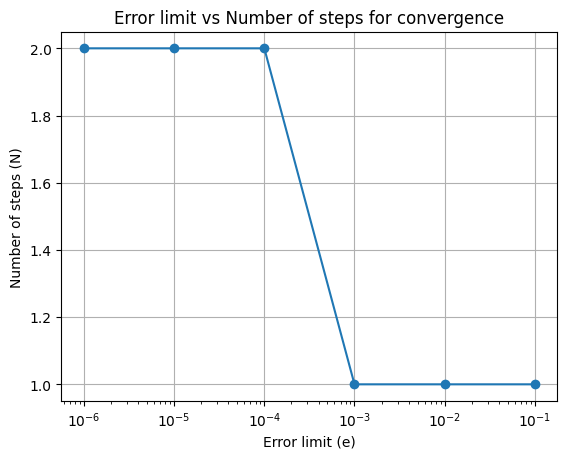

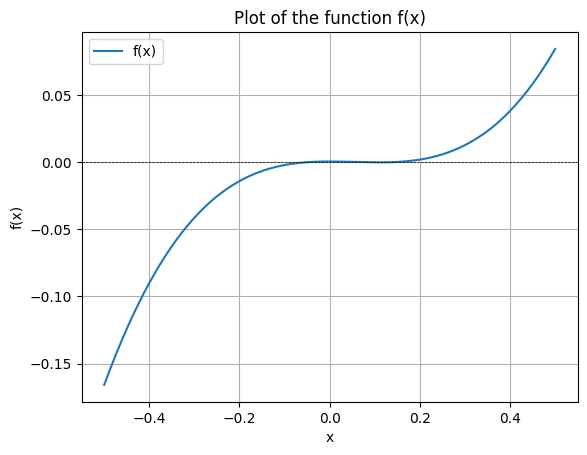

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function and its derivative
def f(x):
    return x**3 - 0.165*x**2 + 3.993e-4

def df(x):
    return 3*x**2 - 0.33*x

# Newton-Raphson method
def newton_raphson(f, df, x0, e, max_iter=1000):
    x = x0
    for i in range(max_iter):
        fx = f(x)
        if abs(fx) < e:
            return x, i+1
        dfx = df(x)
        if dfx == 0:
            print("Zero derivative. No solution found.")
            return None, i+1
        x = x - fx / dfx
    print("Exceeded maximum iterations. No solution found.")
    return None, max_iter

# Initial guesses and error limits
x0_a = 0.05
x0_b = 0.11
e_values = [0.1, 0.01, 0.001, 0.0001, 0.00001, 0.000001]

# Solve for part a and b
solution_a, steps_a = newton_raphson(f, df, x0_a, 0.0001)
solution_b, steps_b = newton_raphson(f, df, x0_b, 0.0001)

print(f"Solution with x0=0.05: {solution_a}, Steps: {steps_a}")
print(f"Solution with x0=0.11: {solution_b}, Steps: {steps_b}")

# Part c: Find another initial guess that leads to no solution
# This can happen if the initial guess leads to a derivative of zero or divergence
x0_c = 0.1
solution_c, steps_c = newton_raphson(f, df, x0_c, 0.0001)
print(f"Solution with x0=0.1: {solution_c}, Steps: {steps_c}")

# Part d: Plot e vs number of steps for convergence
steps_list = []
for e in e_values:
    _, steps = newton_raphson(f, df, x0_a, e)
    steps_list.append(steps)

plt.plot(e_values, steps_list, marker='o')
plt.xscale('log')
plt.xlabel('Error limit (e)')
plt.ylabel('Number of steps (N)')
plt.title('Error limit vs Number of steps for convergence')
plt.grid(True)
plt.show()

# Plot the function to visualize its behavior
x_values = np.linspace(-0.5, 0.5, 400)
y_values = f(x_values)

plt.plot(x_values, y_values, label='f(x)')
plt.axhline(0, color='black', linewidth=0.5, linestyle='--')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Plot of the function f(x)')
plt.legend()
plt.grid(True)
plt.show()

## Q3

Bisection Method:
  Root: 1.7692921161651611
  Iterations: 22
  Function value at root: -1.7596450723189605e-06

Newton-Raphson Method:
  Root: 1.7692923542960053
  Iterations: 4
  Function value at root: 4.2406123057503464e-10


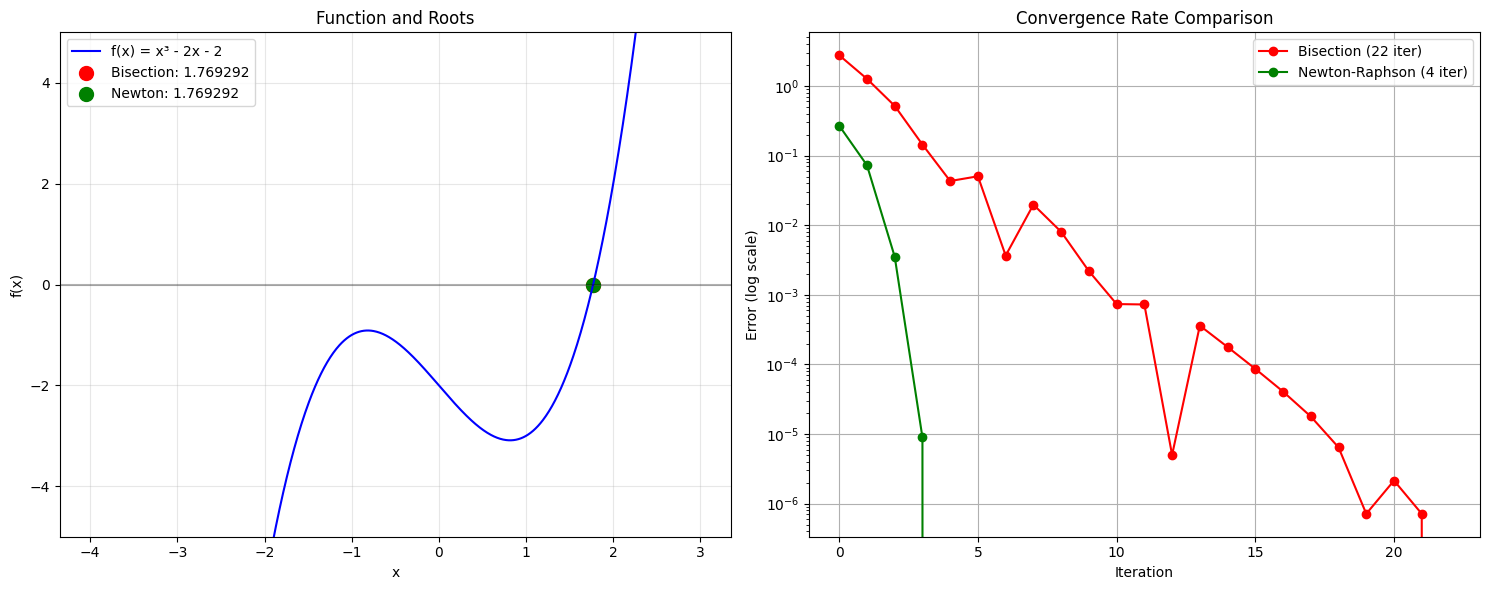


Effectiveness Comparison:
  Newton-Raphson converged in 4 iterations
  Bisection converged in 22 iterations
  Newton-Raphson was 5.5x faster in terms of iterations


In [4]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    """The function: x^3 - 2x - 2 = 0"""
    return x**3 - 2*x - 2

def df(x):
    """The derivative of the function: 3x^2 - 2"""
    return 3*x**2 - 2

def bisection_method(func, a, b, tol=1e-6, max_iter=100):
    """Bisection method for finding roots"""
    if func(a) * func(b) >= 0:
        raise ValueError("The function must have opposite signs at the endpoints a and b.")
    
    iteration = 0
    x_history = []
    
    while (b - a) / 2 > tol and iteration < max_iter:
        c = (a + b) / 2
        x_history.append(c)
        
        if func(c) == 0:
            return c, iteration, x_history
        elif func(a) * func(c) < 0:
            b = c
        else:
            a = c
        iteration += 1
    
    root = (a + b) / 2
    x_history.append(root)
    return root, iteration, x_history

def newton_raphson_method(func, dfunc, x0, tol=1e-6, max_iter=100):
    """Newton-Raphson method for finding roots"""
    iteration = 0
    x = x0
    x_history = [x0]
    
    while abs(func(x)) > tol and iteration < max_iter:
        x = x - func(x) / dfunc(x)
        x_history.append(x)
        iteration += 1
    
    return x, iteration, x_history

# Define interval and initial guess
a, b = -4, 2
x0_newton = 1.5  # Initial guess for Newton-Raphson

# Apply the methods
root_bisection, iterations_bisection, history_bisection = bisection_method(f, a, b)
root_newton, iterations_newton, history_newton = newton_raphson_method(f, df, x0_newton)

# Print results
print(f"Bisection Method:")
print(f"  Root: {root_bisection}")
print(f"  Iterations: {iterations_bisection}")
print(f"  Function value at root: {f(root_bisection)}")
print()
print(f"Newton-Raphson Method:")
print(f"  Root: {root_newton}")
print(f"  Iterations: {iterations_newton}")
print(f"  Function value at root: {f(root_newton)}")

# Calculate errors (distance from final approximation)
errors_bisection = [abs(x - root_bisection) for x in history_bisection]
errors_newton = [abs(x - root_newton) for x in history_newton]

# Create plots to visualize comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: The function and roots
x = np.linspace(-4, 3, 1000)
y = f(x)
ax1.plot(x, y, 'b-', label='f(x) = x³ - 2x - 2')
ax1.axhline(y=0, color='k', linestyle='-', alpha=0.3)
ax1.grid(True, alpha=0.3)
ax1.scatter([root_bisection], [0], color='red', s=100, label=f'Bisection: {root_bisection:.6f}')
ax1.scatter([root_newton], [0], color='green', s=100, label=f'Newton: {root_newton:.6f}')
ax1.set_title('Function and Roots')
ax1.set_xlabel('x')
ax1.set_ylabel('f(x)')
ax1.set_ylim(-5, 5)
ax1.legend()

# Plot 2: Convergence rates
ax2.semilogy(range(len(errors_bisection)), errors_bisection, 'ro-', label=f'Bisection ({iterations_bisection} iter)')
ax2.semilogy(range(len(errors_newton)), errors_newton, 'go-', label=f'Newton-Raphson ({iterations_newton} iter)')
ax2.set_title('Convergence Rate Comparison')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Error (log scale)')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

print("\nEffectiveness Comparison:")
print(f"  Newton-Raphson converged in {iterations_newton} iterations")
print(f"  Bisection converged in {iterations_bisection} iterations")
print(f"  Newton-Raphson was {iterations_bisection/iterations_newton:.1f}x faster in terms of iterations")


## Q4

Analytical reciprocal [0.1, 0.15000000000000002, 0.18750000000000003, 0.19921875000000003, 0.19999694824218753, 0.1999999999534339, 0.20000000000000004, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999999999999998, 0.19999

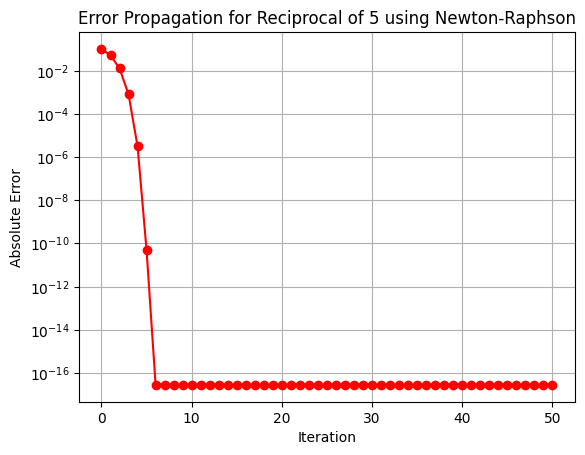

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def newton_raphson_reciprocal(a, x0, iterations=50):
  if a == 0:
    raise ValueError("Division by zero is not allowed.")
  else:
    x_values = [x0]  
    for i in range(iterations):
        x_next = x_values[-1] * (2 - a * x_values[-1])
        x_values.append(x_next)
    return x_values

a = 5
x0 = 0.1 
iterations = 50

x_vals = newton_raphson_reciprocal(a, x0, iterations)
print("Analytical reciprocal",x_vals)

true_reciprocal = 1 / a
print("Actual reciprocal",true_reciprocal)

errors = [abs(x - true_reciprocal) for x in x_vals]


plt.plot(range(iterations + 1), errors, marker='o', linestyle='-', color='r')
plt.yscale('log')  
plt.xlabel("Iteration")
plt.ylabel("Absolute Error")
plt.title(f"Error Propagation for Reciprocal of {a} using Newton-Raphson")
plt.grid(True)
plt.show()

## Q5

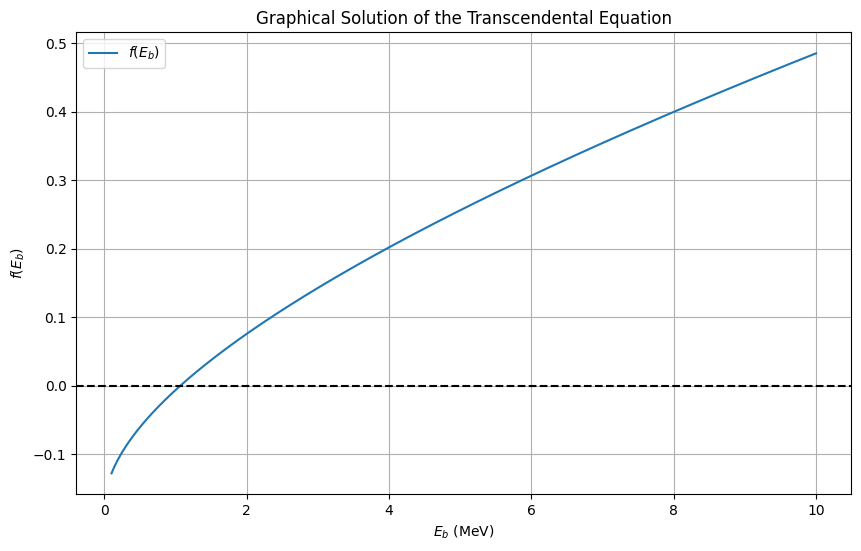


Results:
Bisection: Root = 1.067474 MeV, Iterations = 15
Newton-Raphson: Root = 1.067467 MeV, Iterations = 3
Secant: Root = 1.067467 MeV, Iterations = 5


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Constants
V0 = 60  # MeV (potential depth)
a = 1.45  # fm (potential radius)
m = 938  # MeV/c² (reduced mass)
hbar_c = 200  # MeV·fm

# Define the function f(E_b) = k*cot(ka) + beta
def f(E_b):
    k = np.sqrt(m * (V0 - E_b)) / hbar_c
    beta = np.sqrt(m * E_b) / hbar_c
    ka = k * a
    with np.errstate(divide='ignore', invalid='ignore'):
        cot_ka = np.cos(ka) / np.sin(ka)
    cot_ka = np.nan_to_num(cot_ka, nan=0.0, posinf=0.0, neginf=0.0)
    return k * cot_ka + beta

# Define the derivative of f(E_b)
def df(E_b):
    k = np.sqrt(m * (V0 - E_b)) / hbar_c
    beta = np.sqrt(m * E_b) / hbar_c
    ka = k * a
    cot_ka = np.cos(ka) / np.sin(ka)
    csc_sq_ka = 1.0 / (np.sin(ka)**2 + 1e-12)  # Avoid division by zero
    term1 = -cot_ka / k if k != 0 else 0
    term2 = a * csc_sq_ka
    term3 = 1.0 / beta if beta != 0 else 0
    derivative = (m / (2 * hbar_c**2)) * (term1 + term2 + term3)
    return derivative

# Bisection method
def bisection(f, a, b, tol=1e-6, max_iter=100):
    if f(a) * f(b) >= 0:
        raise ValueError("Function has the same sign at the endpoints.")
    iter_count = 0
    c = a
    for _ in range(max_iter):
        iter_count += 1
        c = (a + b) / 2
        if abs(f(c)) < tol:
            return c, iter_count
        if f(c) * f(a) < 0:
            b = c
        else:
            a = c
    return c, iter_count

# Newton-Raphson method
def newton_raphson(f, df, x0, tol=1e-6, max_iter=100):
    iter_count = 0
    x = x0
    for _ in range(max_iter):
        iter_count += 1
        fx = f(x)
        if abs(fx) < tol:
            return x, iter_count
        dfx = df(x)
        if dfx == 0:
            break
        x -= fx / dfx
    return x, iter_count

# Secant method
def secant(f, x0, x1, tol=1e-6, max_iter=100):
    iter_count = 0
    for _ in range(max_iter):
        iter_count += 1
        fx0 = f(x0)
        fx1 = f(x1)
        if abs(fx1) < tol:
            return x1, iter_count
        if fx1 - fx0 == 0:
            break
        x_new = x1 - fx1 * (x1 - x0) / (fx1 - fx0)
        x0, x1 = x1, x_new
    return x1, iter_count

# Part (a): Plot f(E_b) to find the root graphically
E_b_values = np.linspace(0.1, 10, 1000)
f_values = f(E_b_values)

plt.figure(figsize=(10, 6))
plt.plot(E_b_values, f_values, label='$f(E_b)$')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('$E_b$ (MeV)')
plt.ylabel('$f(E_b)$')
plt.title('Graphical Solution of the Transcendental Equation')
plt.grid(True)
plt.legend()
plt.show()

# Part (b): Find the root using different methods
tol = 1e-6

# Bisection method
a_bisec, b_bisec = 0.5, 1.5
root_bisec, iter_bisec = bisection(f, a_bisec, b_bisec, tol)

# Newton-Raphson
x0_newton = 1.0
root_newton, iter_newton = newton_raphson(f, df, x0_newton, tol)

# Secant method
x0_secant, x1_secant = 0.5, 1.5
root_secant, iter_secant = secant(f, x0_secant, x1_secant, tol)

# Results
print("\nResults:")
print(f"Bisection: Root = {root_bisec:.6f} MeV, Iterations = {iter_bisec}")
print(f"Newton-Raphson: Root = {root_newton:.6f} MeV, Iterations = {iter_newton}")
print(f"Secant: Root = {root_secant:.6f} MeV, Iterations = {iter_secant}")